# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv("../data/co2_emissions.csv")

print(f"Loaded: {len(df)} rows")
print("Countries:", df["Country"].nunique())
print("Years:", df["Year"].min(), "-", df["Year"].max())

df.head()


Loaded: 345 rows
Countries: 15
Years: 2000 - 2022


,Country,Region,Year,CO2_Mt,CO2_per_capita
0,United States,North America,2000,5857.6,1.32
1,United States,North America,2001,5724.0,1.26
2,United States,North America,2002,5652.8,1.11
3,United States,North America,2003,5592.8,1.29
4,United States,North America,2004,5743.2,1.12


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country/countries **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country/countries and its story

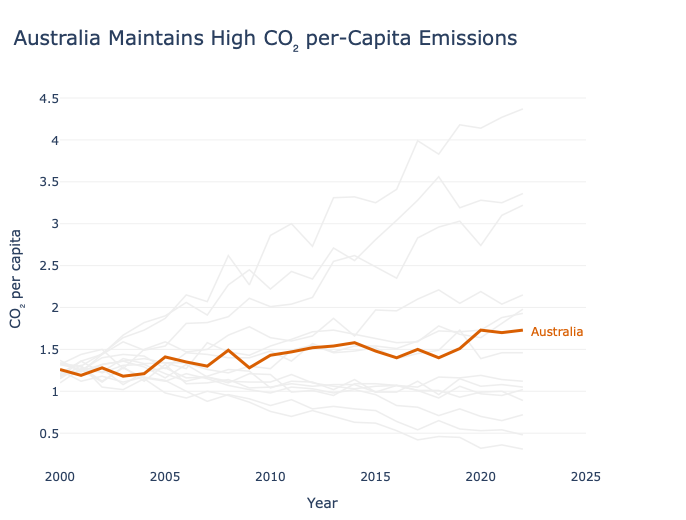

In [2]:
# Task 1 
# YOUR CODE HERE

# Task 1: CO2 per capita for all countries
# Highlight Australia; show all other countries in light grey

highlight_country = "Australia"

fig1 = go.Figure()

# Add all non-highlighted countries in grey
for country in df["Country"].unique():
    country_data = (
        df[df["Country"] == country]
        .sort_values("Year")
    )

    if country != highlight_country:
        fig1.add_trace(
            go.Scatter(
                x=country_data["Year"],
                y=country_data["CO2_per_capita"],
                mode="lines",
                line=dict(color="#EEEEEE", width=1.5),
                name=country,
                showlegend=False,
                hovertemplate=(
                    country + "<br>Year: %{x}"
                    + "<br>CO2 per capita: %{y:.2f}<extra></extra>"
                )
            )
        )

# Add the highlighted country on top
highlight_data = (
    df[df["Country"] == highlight_country]
    .sort_values("Year")
)

fig1.add_trace(
    go.Scatter(
        x=highlight_data["Year"],
        y=highlight_data["CO2_per_capita"],
        mode="lines",
        line=dict(color="#D95F02", width=3),
        name=highlight_country,
        showlegend=False,
        hovertemplate=(
            highlight_country + "<br>Year: %{x}"
            + "<br>CO2 per capita: %{y:.2f}<extra></extra>"
        )
    )
)

# Label the highlighted country at the end of its line
last_point = highlight_data.iloc[-1]

fig1.add_annotation(
    x=last_point["Year"],
    y=last_point["CO2_per_capita"],
    text=highlight_country,
    showarrow=False,
    xshift=35,
    font=dict(size=12, color="#D95F02")
)

# Clean styling
fig1.update_layout(
    template="plotly_white",
    title=dict(
        text="Australia Maintains High CO₂ per-Capita Emissions",
        x=0.02,
        xanchor="left",
        font=dict(size=20)
    ),
    xaxis=dict(
        title="Year",
        showgrid=False,
        showline=False,
        zeroline=False,
        range=[2000, 2025]
    ),
    yaxis=dict(
        title="CO₂ per capita",
        showgrid=True,
        gridcolor="#F0F0F0",
        zeroline=False,
        showline=False
    ),
    margin=dict(l=60, r=100, t=90, b=50),
    height=520,
    hovermode="x unified"
)

fig1.show()


---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

Asian countries in the dataset:
<ArrowStringArray>
['China', 'India', 'Japan', 'South Korea', 'Indonesia']
Length: 5, dtype: str


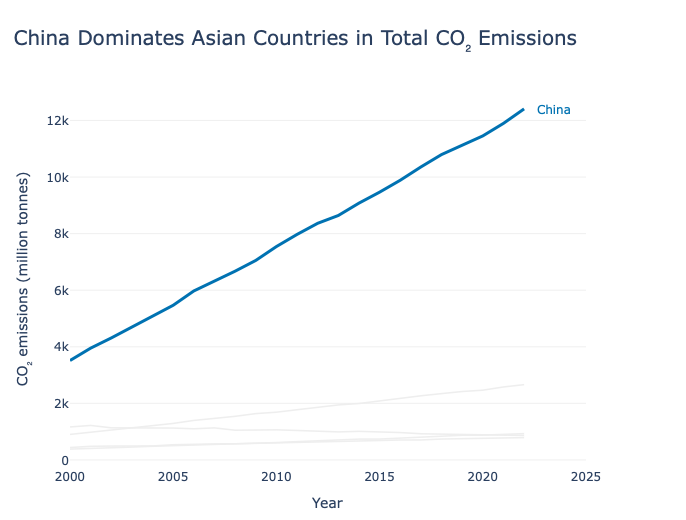

In [3]:
# Task 2 
# YOUR CODE HERE

# Task 2: CO2 emissions over time for Asian countries
# Highlight China; show all other Asian countries in light grey

asia_df = df[df["Region"] == "Asia"].copy()

print("Asian countries in the dataset:")
print(asia_df["Country"].unique())

highlight_country = "China"

fig2 = go.Figure()

# Add all other Asian countries in grey
for country in asia_df["Country"].unique():
    country_data = (
        asia_df[asia_df["Country"] == country]
        .sort_values("Year")
    )

    if country != highlight_country:
        fig2.add_trace(
            go.Scatter(
                x=country_data["Year"],
                y=country_data["CO2_Mt"],
                mode="lines",
                line=dict(color="#EEEEEE", width=1.5),
                name=country,
                showlegend=False,
                hovertemplate=(
                    country + "<br>Year: %{x}"
                    + "<br>CO2 emissions: %{y:,.1f} Mt<extra></extra>"
                )
            )
        )

# Add China as the highlighted line
china_data = (
    asia_df[asia_df["Country"] == highlight_country]
    .sort_values("Year")
)

if not china_data.empty:
    fig2.add_trace(
        go.Scatter(
            x=china_data["Year"],
            y=china_data["CO2_Mt"],
            mode="lines",
            line=dict(color="#0072B2", width=3),
            name=highlight_country,
            showlegend=False,
            hovertemplate=(
                "China<br>Year: %{x}"
                + "<br>CO2 emissions: %{y:,.1f} Mt<extra></extra>"
            )
        )
    )

    # Label China at the end of its line
    last_point = china_data.iloc[-1]

    fig2.add_annotation(
        x=last_point["Year"],
        y=last_point["CO2_Mt"],
        text="China",
        showarrow=False,
        xshift=30,
        font=dict(size=12, color="#0072B2")
    )

# Clean styling
fig2.update_layout(
    template="plotly_white",
    title=dict(
        text="China Dominates Asian Countries in Total CO₂ Emissions",
        x=0.02,
        xanchor="left",
        font=dict(size=20)
    ),
    xaxis=dict(
        title="Year",
        showgrid=False,
        showline=False,
        zeroline=False,
        range=[2000, 2025]
    ),
    yaxis=dict(
        title="CO₂ emissions (million tonnes)",
        showgrid=True,
        gridcolor="#F0F0F0",
        zeroline=False,
        showline=False
    ),
    margin=dict(l=70, r=100, t=90, b=50),
    height=520,
    hovermode="x unified"
)

fig2.show()

